# Classification sensitivity to the fixed query value

This notebook reuses the validated teacher--student circuit from
`05_teacher_student_classification.ipynb` and holds the training-set size
fixed. It answers two complementary questions.

1. **Global alignment:** is classification performance peaked at the query
   used to generate the teacher, along the predeclared path
   \(\boldsymbol f(\lambda)=\lambda\boldsymbol f^\star\)?
2. **Local precision:** how much direction-dependent angular error
   \(\delta=\lVert\boldsymbol f-\boldsymbol f^\star\rVert_2\) can be tolerated
   before accuracy decreases materially?

The two-dimensional local neighborhood is sampled in uniformly spaced
directions. A radial scan alone would be insufficient because equal-norm query
errors need not have equal effects.

For every candidate query, the student is retrained from scratch. Teachers,
training and test points, optimization budgets, and initial parameters are
paired across query values. Folds are averaged within teachers and uncertainty
is obtained by resampling teachers. Test balanced accuracy is the primary
metric; test binary cross-entropy is retained as a smoother diagnostic.

The default `smoke` profile only validates the pipeline. Set
`PROFILE = "paper"`, restart the kernel, and run all cells for manuscript
results.

In [10]:
# =============================================================================
# Configuration
# =============================================================================
from dataclasses import dataclass
from pathlib import Path
import hashlib
import json
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from scipy.optimize import minimize

jax.config.update("jax_enable_x64", True)

N_QUBITS = 2
N_LAYERS = 2
BLOCK = "ry"
F_STAR_PAIR = np.array([np.pi / 4, np.pi / 3])
WRONG_SCALE = 2.0
BETA = 5.0

# The paper profile keeps N fixed at the saturated value from the preceding
# learning-curve experiment. Teachers and data seeds match that notebook.
PROFILE = "paper"
PROFILES = {
    "smoke": dict(
        n_teachers=1,
        n_folds=1,
        n_train=32,
        n_test=1000,
        n_probe=2000,
        n_restarts=2,
        adam_steps=100,
        adam_lr=0.035,
        polish_top=1,
        polish_maxiter=50,
        global_points=5,
        local_deltas=2,
        local_directions=4,
        local_delta_min=1e-3,
        local_delta_max=1e-1,
        bootstrap_samples=200,
    ),
    "paper": dict(
        n_teachers=10,
        n_folds=4,
        n_train=256,
        n_test=20000,
        n_probe=20000,
        n_restarts=12,
        adam_steps=1500,
        adam_lr=0.03,
        polish_top=2,
        polish_maxiter=400,
        global_points=33,
        local_deltas=11,
        local_directions=8,
        local_delta_min=1e-4,
        local_delta_max=5e-1,
        bootstrap_samples=5000,
    ),
}
if PROFILE not in PROFILES:
    raise ValueError(f"unknown PROFILE={PROFILE!r}")
P = PROFILES[PROFILE]

TEACHER_SEEDS = list(range(P["n_teachers"]))
BALANCE = (0.4, 0.6)
MIN_NONSEP = 0.2
MAX_TEACHER_DRAWS = 4000
BASE_SEED = 1729
ACCURACY_DROP = 0.01

OUTDIR = Path("./query_sensitivity_outputs")
OUTDIR.mkdir(parents=True, exist_ok=True)

print(
    f"profile={PROFILE} | block={BLOCK} | teachers={P['n_teachers']} | "
    f"folds={P['n_folds']} | N_train={P['n_train']}"
)
if PROFILE != "paper":
    print("SMOKE PROFILE: do not report its numerical output.")

profile=paper | block=ry | teachers=10 | folds=4 | N_train=256


## Fixed circuit and teacher family

For two qubits and two reuploading layers,

\[
U(\boldsymbol x,\boldsymbol f;\boldsymbol\theta)
=
\prod_{\ell=1}^{2}
V_\ell(\boldsymbol\theta)
Q_\ell(\boldsymbol f)
W_\ell(\boldsymbol\theta)
E_x(\boldsymbol x),
\]

where
\(E_x(\boldsymbol x)=R_{Z_0}(x_0)R_{Z_1}(x_1)\),
\((s_1,s_2)=(1,2)\), and

\[
Q_\ell(\boldsymbol f)
=R_{Z_0Y_1}(s_\ell f_1)R_{Y_0Z_1}(s_\ell f_0).
\]

The trainable blocks are products of single-qubit \(R_Y\) rotations, giving
eight free parameters. Inputs are sampled uniformly from
\([0,2\pi)^2\), the initial state is \(\lvert ++\rangle\), and the measured
observable is \(Z_0Z_1\). The teacher query is
\(\boldsymbol f^\star=(\pi/4,\pi/3)\).

In [11]:
# =============================================================================
# Circuit implementation
# =============================================================================
_I = np.eye(2, dtype=complex)
_Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
_Z = np.diag([1, -1]).astype(complex)


def rng_from(*parts):
    return np.random.default_rng(
        np.random.SeedSequence([int(part) for part in parts])
    )


@dataclass(frozen=True)
class Cfg:
    n_qubits: int = 2
    n_layers: int = 2
    block: str = "ry"

    def __post_init__(self):
        if self.n_qubits % 2:
            raise ValueError("the YZ/ZY dimer construction needs an even n_qubits")
        if self.block not in {"ry", "yzy"}:
            raise ValueError("block must be 'ry' or 'yzy'")

    @property
    def n_dimers(self):
        return self.n_qubits // 2

    @property
    def dimers(self):
        return [(2 * d, 2 * d + 1) for d in range(self.n_dimers)]

    @property
    def scales(self):
        return np.arange(1, self.n_layers + 1, dtype=float)

    @property
    def n_params(self):
        per_single_qubit = 1 if self.block == "ry" else 3
        return self.n_layers * 2 * self.n_qubits * per_single_qubit

    def expand(self, free_parameters):
        free_parameters = jnp.asarray(free_parameters).ravel()
        shape = (self.n_layers, 2, self.n_qubits)
        if self.block == "yzy":
            return free_parameters.reshape(*shape, 3)
        return jnp.zeros((*shape, 3)).at[:, :, :, 1].set(
            free_parameters.reshape(*shape)
        )

    def free(self, full_parameters):
        full = np.asarray(full_parameters).reshape(
            self.n_layers, 2, self.n_qubits, 3
        )
        if self.block == "yzy":
            return full.ravel()
        return full[:, :, :, 1].ravel()


CFG = Cfg(N_QUBITS, N_LAYERS, BLOCK)


def make_f_star(n_qubits):
    return np.tile(F_STAR_PAIR, n_qubits // 2).astype(float)


F_STAR = make_f_star(CFG.n_qubits)
ARMS = {
    "correct": F_STAR.copy(),
    "wrong": WRONG_SCALE * F_STAR,
    "none": np.zeros_like(F_STAR),
}


def kron_all_numpy(matrices):
    out = np.array([[1.0]], dtype=complex)
    for matrix in matrices:
        out = np.kron(out, matrix)
    return out


def query_generators(n_qubits):
    generators = []
    for i, j in [(2 * d, 2 * d + 1) for d in range(n_qubits // 2)]:
        for left, right in ((_Y, _Z), (_Z, _Y)):
            matrices = [_I] * n_qubits
            matrices[i], matrices[j] = left, right
            generators.append(kron_all_numpy(matrices))
    return generators


def maximum_generator_commutator(n_qubits):
    generators = query_generators(n_qubits)
    return max(
        float(np.max(np.abs(a @ b - b @ a)))
        for i, a in enumerate(generators)
        for b in generators[i + 1 :]
    )


def basis_signs(n_qubits):
    indices = np.arange(2**n_qubits)
    bits = (
        indices[:, None]
        >> np.arange(n_qubits - 1, -1, -1)[None, :]
    ) & 1
    return 1.0 - 2.0 * bits


def _su2_jax(parameters):
    a, b, c = parameters
    rz = lambda angle: jnp.diag(
        jnp.array(
            [jnp.exp(-0.5j * angle), jnp.exp(0.5j * angle)],
            dtype=jnp.complex128,
        )
    )
    cosine = jnp.cos(b / 2).astype(jnp.complex128)
    sine = jnp.sin(b / 2).astype(jnp.complex128)
    ry = jnp.array([[cosine, -sine], [sine, cosine]], dtype=jnp.complex128)
    return rz(c) @ ry @ rz(a)


def _kron_jax(matrices):
    out = jnp.eye(1, dtype=jnp.complex128)
    for matrix in matrices:
        out = jnp.kron(out, matrix)
    return out


def _query_jax(f, scale, cfg):
    yz = jnp.asarray(np.kron(_Y, _Z))
    zy = jnp.asarray(np.kron(_Z, _Y))
    identity = jnp.eye(4, dtype=jnp.complex128)

    def rotation(angle, generator):
        return (
            jnp.cos(angle / 2).astype(jnp.complex128) * identity
            - 1j * jnp.sin(angle / 2).astype(jnp.complex128) * generator
        )

    dimer_gates = []
    for dimer in range(cfg.n_dimers):
        f0, f1 = f[2 * dimer], f[2 * dimer + 1]
        dimer_gates.append(
            rotation(scale * f1, zy) @ rotation(scale * f0, yz)
        )
    return _kron_jax(dimer_gates)


def forward(full_parameters, x, f, cfg=CFG):
    dimension = 2**cfg.n_qubits
    signs = basis_signs(cfg.n_qubits)
    parity = jnp.asarray(np.prod(signs, axis=1))
    initial = jnp.full(
        (dimension,), 1.0 / np.sqrt(dimension), dtype=jnp.complex128
    )

    theta = jnp.asarray(full_parameters).reshape(
        cfg.n_layers, 2, cfg.n_qubits, 3
    )
    x = jnp.atleast_2d(jnp.asarray(x))
    f = jnp.asarray(f)
    data_phase = jnp.exp(-0.5j * (x @ jnp.asarray(signs).T))

    state = jnp.broadcast_to(initial, (x.shape[0], dimension))
    for layer in range(cfg.n_layers):
        state = state * data_phase
        w_layer = _kron_jax(
            [_su2_jax(theta[layer, 0, q]) for q in range(cfg.n_qubits)]
        )
        state = state @ w_layer.T
        state = state @ _query_jax(f, cfg.scales[layer], cfg).T
        v_layer = _kron_jax(
            [_su2_jax(theta[layer, 1, q]) for q in range(cfg.n_qubits)]
        )
        state = state @ v_layer.T

    return jnp.real(jnp.sum(jnp.abs(state) ** 2 * parity, axis=1))


def sample_free_prior(rng, cfg=CFG):
    if cfg.block == "ry":
        return rng.uniform(-np.pi, np.pi, cfg.n_params)

    shape = (cfg.n_layers, 2, cfg.n_qubits)
    a = rng.uniform(0.0, 2 * np.pi, shape)
    c = rng.uniform(0.0, 2 * np.pi, shape)
    b = np.arccos(1.0 - 2.0 * rng.uniform(0.0, 1.0, shape))
    return np.stack([a, b, c], axis=-1).ravel()


def fourier_matrix(full_parameters, f, cfg=CFG, dimer=0):
    modes_per_axis = 2 * cfg.n_layers + 1
    sub_cfg = Cfg(2, cfg.n_layers, cfg.block)
    i, j = cfg.dimers[dimer]
    theta = np.asarray(full_parameters).reshape(
        cfg.n_layers, 2, cfg.n_qubits, 3
    )[:, :, [i, j], :]
    f_sub = np.asarray(f)[[i, j]]
    grid = 2 * np.pi * np.arange(modes_per_axis) / modes_per_axis
    x0, x1 = np.meshgrid(grid, grid, indexing="ij")
    points = np.stack([x0.ravel(), x1.ravel()], axis=1)
    values = np.asarray(forward(theta, points, f_sub, sub_cfg)).reshape(
        modes_per_axis, modes_per_axis
    )
    return np.fft.fftshift(
        np.fft.fft2(values) / modes_per_axis**2
    )


def coefficient_nonseparability(full_parameters, f, cfg=CFG):
    result = {}
    for dimer in range(cfg.n_dimers):
        singular_values = np.linalg.svd(
            fourier_matrix(full_parameters, f, cfg, dimer),
            compute_uv=False,
        )
        result[f"dimer{dimer}"] = float(
            1.0
            - singular_values[0] ** 2
            / np.sum(singular_values**2)
        )
    result["min"] = min(
        result[f"dimer{d}"] for d in range(cfg.n_dimers)
    )
    return result


def operator_nonseparable_weight(gate):
    reshuffled = (
        np.asarray(gate)
        .reshape(2, 2, 2, 2)
        .transpose(0, 2, 1, 3)
        .reshape(4, 4)
    )
    singular_values = np.linalg.svd(reshuffled, compute_uv=False)
    weights = singular_values**2
    return float(1.0 - weights[0] / np.sum(weights))


assert maximum_generator_commutator(CFG.n_qubits) < 1e-12
unit_rng = rng_from(BASE_SEED, 1)
unit_w = sample_free_prior(unit_rng, CFG)
unit_theta = np.asarray(CFG.expand(unit_w))
unit_x = unit_rng.uniform(0, 2 * np.pi, (64, CFG.n_qubits))
unit_values = np.asarray(forward(unit_theta, unit_x, F_STAR, CFG))
assert np.max(np.abs(unit_values)) <= 1.0 + 1e-10
assert coefficient_nonseparability(
    unit_theta, np.zeros_like(F_STAR), CFG
)["min"] < 1e-10
generic_query = np.asarray(_query_jax(F_STAR, 1.0, CFG))
if CFG.n_qubits == 2:
    assert operator_nonseparable_weight(generic_query) > 1e-3

print(
    f"circuit checks passed | n_params={CFG.n_params} | "
    f"f*={np.round(F_STAR, 4)} | wrong={np.round(ARMS['wrong'], 4)}"
)

circuit checks passed | n_params=8 | f*=[0.7854 1.0472] | wrong=[1.5708 2.0944]


## Teacher ensemble

Teacher parameters are drawn from the same free-parameter prior used for
student initialization. The predeclared balance and Fourier-nonseparability
filters are identical to those in the learning-curve experiment. Selection
uses an independent probe set; no training or test point participates.

In [12]:
# =============================================================================
# Teacher selection
# =============================================================================
def select_teacher(
    cfg,
    f_star,
    teacher_seed,
    *,
    n_probe,
    balance=BALANCE,
    min_nonsep=MIN_NONSEP,
    max_draws=MAX_TEACHER_DRAWS,
):
    probe_rng = rng_from(BASE_SEED, 100, teacher_seed)
    parameter_rng = rng_from(BASE_SEED, 101, teacher_seed)
    x_probe = probe_rng.uniform(
        0, 2 * np.pi, (n_probe, cfg.n_qubits)
    )

    for draw in range(1, max_draws + 1):
        free_parameters = sample_free_prior(parameter_rng, cfg)
        full_parameters = np.asarray(cfg.expand(free_parameters))
        score = np.asarray(forward(full_parameters, x_probe, f_star, cfg))
        positive_fraction = float(np.mean(score > 0))
        if not (balance[0] < positive_fraction < balance[1]):
            continue

        nonseparability = coefficient_nonseparability(
            full_parameters, f_star, cfg
        )
        if nonseparability["min"] <= min_nonsep:
            continue

        return {
            "teacher": int(teacher_seed),
            "draws": int(draw),
            "free_parameters": np.asarray(free_parameters),
            "full_parameters": full_parameters,
            "balance": positive_fraction,
            "nonseparability": nonseparability,
            "boundary_mass_005": float(np.mean(np.abs(score) < 0.05)),
        }

    raise RuntimeError(
        f"teacher {teacher_seed} did not pass the predeclared criteria "
        f"in {max_draws} draws"
    )


t0 = time.time()
TEACHERS = [
    select_teacher(
        CFG,
        F_STAR,
        seed,
        n_probe=P["n_probe"],
    )
    for seed in TEACHER_SEEDS
]

teacher_table = pd.DataFrame(
    [
        {
            "teacher": t["teacher"],
            "draws": t["draws"],
            "balance": t["balance"],
            "nonseparability": t["nonseparability"]["min"],
            "boundary_mass_005": t["boundary_mass_005"],
        }
        for t in TEACHERS
    ]
)
print(teacher_table.to_string(index=False))
print(f"selected {len(TEACHERS)} teachers in {time.time() - t0:.1f}s")

 teacher  draws  balance  nonseparability  boundary_mass_005
       0      1  0.44610         0.252383            0.08915
       1      5  0.43815         0.595118            0.11495
       2      2  0.51450         0.271047            0.04985
       3      1  0.53520         0.467105            0.09780
       4      5  0.52015         0.521541            0.08865
       5      4  0.43140         0.509167            0.06320
       6      3  0.44020         0.522358            0.10470
       7      3  0.49605         0.322941            0.06630
       8      4  0.42420         0.545583            0.09600
       9      1  0.48375         0.596251            0.06025
selected 10 teachers in 0.8s


## Query scans

The global scan follows

\[
\boldsymbol f(\lambda)=\lambda\boldsymbol f^\star,
\qquad \lambda\in[0,2].
\]

It includes exactly \(\lambda=0\), \(1\), and \(2\), corresponding to the
no-query, correct-query, and previously used wrong-query arms.

The local scan uses logarithmically spaced radii and uniformly spaced
directions,

\[
\boldsymbol f(\delta,\phi_k)
=\operatorname{wrap}_{[-\pi,\pi)}\!\left[
\boldsymbol f^\star+
\delta(\cos\phi_k,\sin\phi_k)
\right],
\qquad
\phi_k=\frac{2\pi k}{K}.
\]

Thus \(\delta\) is the angular mismatch on the query torus in the local range
considered here. The local grid excludes \(\delta=0\), which cannot be shown
on a logarithmic axis; its accuracy is taken from the exactly included
\(\lambda=1\) global point.

In [13]:
# =============================================================================
# Predeclared query grids
# =============================================================================
def wrap_angles(f):
    f = np.asarray(f, dtype=float)
    return (f + np.pi) % (2 * np.pi) - np.pi


def make_query_table():
    rows = []

    # linspace contains lambda=1 for the chosen odd grid sizes; concatenate it
    # explicitly so future edits cannot accidentally remove the baseline.
    lambdas = np.unique(
        np.concatenate(
            [np.linspace(0.0, 2.0, P["global_points"]), [0.0, 1.0, 2.0]]
        )
    )
    for index, lam in enumerate(lambdas):
        f = lam * F_STAR
        rows.append(
            dict(
                scan="global",
                query_id=f"g{index:03d}",
                candidate=index,
                query_scale=float(lam),
                delta=np.nan,
                direction=np.nan,
                phi=np.nan,
                f0=float(f[0]),
                f1=float(f[1]),
            )
        )

    deltas = np.geomspace(
        P["local_delta_min"],
        P["local_delta_max"],
        P["local_deltas"],
    )
    phis = 2 * np.pi * np.arange(P["local_directions"]) / P["local_directions"]
    candidate = 0
    for delta_index, delta in enumerate(deltas):
        for direction, phi in enumerate(phis):
            displacement = delta * np.array([np.cos(phi), np.sin(phi)])
            f = wrap_angles(F_STAR + displacement)
            rows.append(
                dict(
                    scan="local",
                    query_id=f"l{delta_index:03d}d{direction:02d}",
                    candidate=candidate,
                    query_scale=np.nan,
                    delta=float(delta),
                    direction=int(direction),
                    phi=float(phi),
                    f0=float(f[0]),
                    f1=float(f[1]),
                )
            )
            candidate += 1

    return pd.DataFrame(rows)


QUERY_TABLE = make_query_table()
GLOBAL_QUERIES = QUERY_TABLE[QUERY_TABLE["scan"] == "global"].copy()
LOCAL_QUERIES = QUERY_TABLE[QUERY_TABLE["scan"] == "local"].copy()

assert np.count_nonzero(np.isclose(GLOBAL_QUERIES["query_scale"], 1.0)) == 1
assert np.allclose(
    np.sqrt(
        (LOCAL_QUERIES["f0"].to_numpy() - F_STAR[0]) ** 2
        + (LOCAL_QUERIES["f1"].to_numpy() - F_STAR[1]) ** 2
    ),
    LOCAL_QUERIES["delta"],
)

print(
    f"global queries={len(GLOBAL_QUERIES)} | "
    f"local queries={len(LOCAL_QUERIES)} "
    f"({P['local_deltas']} radii x {P['local_directions']} directions)"
)
display(QUERY_TABLE.head())

global queries=33 | local queries=88 (11 radii x 8 directions)


,scan,query_id,candidate,query_scale,delta,direction,phi,f0,f1
0,global,g000,0,0.0000,NaN,NaN,NaN,0.000000,0.000000
1,global,g001,1,0.0625,NaN,NaN,NaN,0.049087,0.065450
2,global,g002,2,0.1250,NaN,NaN,NaN,0.098175,0.130900
3,global,g003,3,0.1875,NaN,NaN,NaN,0.147262,0.196350
4,global,g004,4,0.2500,NaN,NaN,NaN,0.196350,0.261799


## Classification training

Teacher labels are

\[
y(\boldsymbol x)=\mathbb 1[v^\star(\boldsymbol x)>0],
\]

and the student probability is

\[
p_{\boldsymbol\theta}(y=1\mid\boldsymbol x)
=\sigma[\beta v(\boldsymbol x,\boldsymbol f;\boldsymbol\theta)],
\qquad \beta=5.
\]

Every query receives the same fixed number of full-batch Adam steps and the
same L-BFGS polishing budget. Initial parameters are paired across all queries
within a teacher--fold pair, but parameters are never transferred between
queries. Model selection uses training BCE only.

In [14]:
# =============================================================================
# Classification optimizer and metrics
# =============================================================================
def bce_from_logits(logits, labels):
    labels = jnp.asarray(labels)
    return jnp.mean(jax.nn.softplus(logits) - labels * logits)


def classification_loss(free_parameters, x, labels, f, cfg=CFG, beta=BETA):
    score = forward(cfg.expand(free_parameters), x, f, cfg)
    return bce_from_logits(beta * score, labels)


def make_batched_adam(
    cfg,
    *,
    beta,
    n_steps,
    learning_rate,
    gradient_clip=10.0,
):
    def loss_one(parameters, x, labels, f):
        return classification_loss(parameters, x, labels, f, cfg, beta)

    value_and_gradient = jax.vmap(
        jax.value_and_grad(loss_one),
        in_axes=(0, None, None, None),
    )

    @jax.jit
    def run(initial_parameters, x, labels, f):
        parameters = jnp.asarray(initial_parameters)
        first_moment = jnp.zeros_like(parameters)
        second_moment = jnp.zeros_like(parameters)

        def body(step, state):
            parameters, first_moment, second_moment = state
            _, gradient = value_and_gradient(parameters, x, labels, f)

            norms = jnp.linalg.norm(gradient, axis=1, keepdims=True)
            gradient = gradient * jnp.minimum(
                1.0, gradient_clip / (norms + 1e-12)
            )

            first_moment = 0.9 * first_moment + 0.1 * gradient
            second_moment = 0.999 * second_moment + 0.001 * gradient**2
            t = step + 1
            first_corrected = first_moment / (1.0 - 0.9**t)
            second_corrected = second_moment / (1.0 - 0.999**t)

            fraction = step / jnp.maximum(1, n_steps - 1)
            rate = learning_rate * (
                0.1 + 0.9 * 0.5 * (1.0 + jnp.cos(jnp.pi * fraction))
            )
            parameters = parameters - rate * first_corrected / (
                jnp.sqrt(second_corrected) + 1e-8
            )
            return parameters, first_moment, second_moment

        parameters, _, _ = jax.lax.fori_loop(
            0,
            n_steps,
            body,
            (parameters, first_moment, second_moment),
        )
        losses = jax.vmap(loss_one, in_axes=(0, None, None, None))(
            parameters, x, labels, f
        )
        return parameters, losses

    return run


ADAM_RUNNER = make_batched_adam(
    CFG,
    beta=BETA,
    n_steps=P["adam_steps"],
    learning_rate=P["adam_lr"],
)


CLASSIFICATION_VALUE_GRAD = jax.jit(
    jax.value_and_grad(
        lambda w, x, labels, f: classification_loss(
            w, x, labels, f, CFG, BETA
        )
    )
)


def balanced_accuracy(labels, predictions):
    labels = np.asarray(labels, dtype=bool)
    predictions = np.asarray(predictions, dtype=bool)
    positive = labels
    negative = ~labels
    if not np.any(positive) or not np.any(negative):
        return np.nan
    sensitivity = np.mean(predictions[positive])
    specificity = np.mean(~predictions[negative])
    return float(0.5 * (sensitivity + specificity))


def evaluate_classifier(free_parameters, x, labels, f, cfg=CFG, beta=BETA):
    score = np.asarray(forward(cfg.expand(free_parameters), x, f, cfg))
    logits = beta * score
    labels = np.asarray(labels, dtype=float)
    predictions = logits > 0
    bce = float(
        np.mean(np.logaddexp(0.0, logits) - labels * logits)
    )
    return {
        "bce": bce,
        "accuracy": float(np.mean(predictions == labels)),
        "balanced_accuracy": balanced_accuracy(labels, predictions),
    }


def fit_classifier(
    cfg,
    f,
    x_train,
    y_train,
    x_test,
    y_test,
    *,
    seed,
    extra_start=None,
):
    rng = rng_from(BASE_SEED, 300, seed)
    initial = np.stack(
        [sample_free_prior(rng, cfg) for _ in range(P["n_restarts"])]
    )
    if extra_start is not None:
        initial[0] = np.asarray(extra_start)

    adam_parameters, adam_losses = ADAM_RUNNER(
        jnp.asarray(initial),
        jnp.asarray(x_train),
        jnp.asarray(y_train),
        jnp.asarray(f),
    )
    candidates = np.asarray(adam_parameters)
    losses = np.asarray(adam_losses)
    best_index = int(np.argmin(losses))
    best_parameters = candidates[best_index].copy()
    best_loss = float(losses[best_index])

    x_jax = jnp.asarray(x_train)
    y_jax = jnp.asarray(y_train)
    f_jax = jnp.asarray(f)

    def value_and_jacobian(parameters):
        value, gradient = CLASSIFICATION_VALUE_GRAD(
            jnp.asarray(parameters), x_jax, y_jax, f_jax
        )
        return float(value), np.asarray(gradient, dtype=float)

    polish_indices = np.argsort(losses)[: P["polish_top"]]
    polish_successes = 0
    for index in polish_indices:
        result = minimize(
            value_and_jacobian,
            candidates[index],
            jac=True,
            method="L-BFGS-B",
            options={
                "maxiter": P["polish_maxiter"],
                "ftol": 1e-12,
                "gtol": 1e-9,
            },
        )
        if result.success:
            polish_successes += 1
        if float(result.fun) < best_loss:
            best_loss = float(result.fun)
            best_parameters = np.asarray(result.x)

    train_metrics = evaluate_classifier(
        best_parameters, x_train, y_train, f, cfg
    )
    test_metrics = evaluate_classifier(
        best_parameters, x_test, y_test, f, cfg
    )
    return {
        "free_parameters": best_parameters,
        "train_bce": train_metrics["bce"],
        "train_accuracy": train_metrics["accuracy"],
        "train_balanced_accuracy": train_metrics["balanced_accuracy"],
        "test_bce": test_metrics["bce"],
        "test_accuracy": test_metrics["accuracy"],
        "test_balanced_accuracy": test_metrics["balanced_accuracy"],
        "polish_successes": int(polish_successes),
    }

## Paired, resumable experiment

For a given teacher, the test set is fixed across all folds and queries. For a
given teacher--fold pair, the training set and initial parameter ensemble are
also fixed across all queries. Consequently, differences along either scan are
paired differences rather than comparisons between independently generated
experiments.

Raw results are checkpointed after every fit. The output filename contains a
hash of the full numerical specification, preventing results from incompatible
configurations from being combined.

In [15]:
# =============================================================================
# Paired query-sensitivity experiment with checkpointing
# =============================================================================
RUN_SPEC = {
    "profile": PROFILE,
    "n_qubits": CFG.n_qubits,
    "n_layers": CFG.n_layers,
    "block": CFG.block,
    "f_star": F_STAR.tolist(),
    "beta": BETA,
    "base_seed": BASE_SEED,
    "balance": list(BALANCE),
    "min_nonseparability": MIN_NONSEP,
    "settings": P,
    "queries": QUERY_TABLE.replace({np.nan: None}).to_dict(orient="records"),
}
RUN_ID = hashlib.sha256(
    json.dumps(RUN_SPEC, sort_keys=True).encode("utf-8")
).hexdigest()[:12]
RESULT_PATH = OUTDIR / f"query_sensitivity_{PROFILE}_{RUN_ID}.csv"
CONFIG_PATH = OUTDIR / f"query_sensitivity_{PROFILE}_{RUN_ID}_config.json"
CONFIG_PATH.write_text(json.dumps(RUN_SPEC, indent=2))


def completed_keys(path):
    if not path.exists():
        return set()
    previous = pd.read_csv(path)
    return set(
        zip(
            previous["teacher"].astype(int),
            previous["fold"].astype(int),
            previous["query_id"].astype(str),
        )
    )


def append_checkpoint(row, path):
    pd.DataFrame([row]).to_csv(
        path,
        mode="a",
        header=not path.exists(),
        index=False,
    )


def run_query_sensitivity(cfg, teachers, queries):
    completed = completed_keys(RESULT_PATH)
    total = len(teachers) * P["n_folds"] * len(queries)
    done = len(completed)
    t0 = time.time()

    for teacher in teachers:
        teacher_id = int(teacher["teacher"])
        theta_star = teacher["full_parameters"]

        test_rng = rng_from(BASE_SEED, 400, teacher_id)
        x_test = test_rng.uniform(
            0, 2 * np.pi, (P["n_test"], cfg.n_qubits)
        )
        teacher_test_score = np.asarray(
            forward(theta_star, x_test, F_STAR, cfg)
        )
        y_test = (teacher_test_score > 0).astype(float)

        for fold in range(P["n_folds"]):
            train_rng = rng_from(BASE_SEED, 401, teacher_id, fold)
            x_train = train_rng.uniform(
                0, 2 * np.pi, (P["n_train"], cfg.n_qubits)
            )
            teacher_train_score = np.asarray(
                forward(theta_star, x_train, F_STAR, cfg)
            )
            y_train = (teacher_train_score > 0).astype(float)

            # This seed deliberately excludes the candidate query: every
            # query receives exactly the same initial parameter ensemble.
            paired_seed = 1_000_000 * teacher_id + 10_000 * fold + P["n_train"]

            for query in queries.itertuples(index=False):
                key = (teacher_id, fold, str(query.query_id))
                if key in completed:
                    continue

                f = np.array([query.f0, query.f1], dtype=float)
                fit = fit_classifier(
                    cfg,
                    f,
                    x_train,
                    y_train,
                    x_test,
                    y_test,
                    seed=paired_seed,
                    extra_start=None,
                )
                row = {
                    "run_id": RUN_ID,
                    "teacher": teacher_id,
                    "fold": int(fold),
                    "n_train": int(P["n_train"]),
                    "scan": query.scan,
                    "query_id": query.query_id,
                    "candidate": int(query.candidate),
                    "query_scale": query.query_scale,
                    "delta": query.delta,
                    "direction": query.direction,
                    "phi": query.phi,
                    "f0": query.f0,
                    "f1": query.f1,
                    **{
                        key: value
                        for key, value in fit.items()
                        if key != "free_parameters"
                    },
                }
                append_checkpoint(row, RESULT_PATH)
                completed.add(key)
                done += 1
                print(
                    f"{done:05d}/{total:05d} | teacher={teacher_id:02d} "
                    f"fold={fold:02d} {query.query_id} | "
                    f"bal.acc={fit['test_balanced_accuracy']:.4f}",
                    flush=True,
                )

    return pd.read_csv(RESULT_PATH)


t0 = time.time()
RAW_RESULTS = run_query_sensitivity(CFG, TEACHERS, QUERY_TABLE)
print(
    f"loaded {len(RAW_RESULTS)} completed fits from {RESULT_PATH} | "
    f"this call: {time.time() - t0:.1f}s"
)

00001/04840 | teacher=00 fold=00 g000 | bal.acc=0.7536
00002/04840 | teacher=00 fold=00 g001 | bal.acc=0.8833
00003/04840 | teacher=00 fold=00 g002 | bal.acc=0.9195
00004/04840 | teacher=00 fold=00 g003 | bal.acc=0.9413
00005/04840 | teacher=00 fold=00 g004 | bal.acc=0.9367
00006/04840 | teacher=00 fold=00 g005 | bal.acc=0.9340
00007/04840 | teacher=00 fold=00 g006 | bal.acc=0.9143
00008/04840 | teacher=00 fold=00 g007 | bal.acc=0.9194
00009/04840 | teacher=00 fold=00 g008 | bal.acc=0.9227
00010/04840 | teacher=00 fold=00 g009 | bal.acc=0.9251
00011/04840 | teacher=00 fold=00 g010 | bal.acc=0.9284
00012/04840 | teacher=00 fold=00 g011 | bal.acc=0.9300
00013/04840 | teacher=00 fold=00 g012 | bal.acc=0.9307
00014/04840 | teacher=00 fold=00 g013 | bal.acc=0.9328
00015/04840 | teacher=00 fold=00 g014 | bal.acc=0.9361
00016/04840 | teacher=00 fold=00 g015 | bal.acc=0.9378
00017/04840 | teacher=00 fold=00 g016 | bal.acc=0.9355
00018/04840 | teacher=00 fold=00 g017 | bal.acc=0.9332
00019/0484

## Teacher-level aggregation and query tolerance

Folds are first averaged within each teacher. The global curve is then averaged
over teachers. For the local scan, two summaries are reported:

- the **directional mean**, which measures typical sensitivity;
- the **per-teacher worst direction**, which gives a conservative precision
  criterion.

Bootstrap resampling is performed only over teachers. Directional spread is a
property of the response surface and is therefore kept distinct from the
bootstrap confidence interval.

The robust one-percentage-point tolerance is

\[
\delta_{1\%}
=\sup\{\delta:
A_{\mathrm{worst}}(\delta)\geq A^\star-0.01\}.
\]

It is evaluated using the first downward crossing of a nonincreasing envelope
of the sampled worst-direction curve. This prevents small optimization or test
noise from creating a spurious recovery at larger mismatch.

In [16]:
# =============================================================================
# Paired teacher-level aggregation
# =============================================================================
PRIMARY_METRIC = "test_balanced_accuracy"


def fold_average(results, group_columns, metric=PRIMARY_METRIC):
    return (
        results.groupby(["teacher", *group_columns], as_index=False)[metric]
        .mean()
        .sort_values(["teacher", *group_columns])
    )


def bootstrap_mean_matrix(values, n_bootstrap, seed):
    values = np.asarray(values, dtype=float)
    rng = rng_from(BASE_SEED, 500, seed)
    indices = rng.integers(
        0, values.shape[0], (n_bootstrap, values.shape[0])
    )
    draws = values[indices].mean(axis=1)
    return {
        "mean": values.mean(axis=0),
        "lower": np.quantile(draws, 0.025, axis=0),
        "upper": np.quantile(draws, 0.975, axis=0),
        "draws": draws,
    }


global_fold = fold_average(
    RAW_RESULTS[RAW_RESULTS["scan"] == "global"], ["query_scale"]
)
global_pivot = global_fold.pivot(
    index="teacher", columns="query_scale", values=PRIMARY_METRIC
).sort_index(axis=1)
GLOBAL_X = global_pivot.columns.to_numpy(dtype=float)
GLOBAL_SUMMARY = bootstrap_mean_matrix(
    global_pivot.to_numpy(), P["bootstrap_samples"], seed=1
)

local_fold_direction = fold_average(
    RAW_RESULTS[RAW_RESULTS["scan"] == "local"],
    ["delta", "direction"],
)

# Typical response: average directions within each teacher.
local_teacher_mean = (
    local_fold_direction.groupby(["teacher", "delta"], as_index=False)[
        PRIMARY_METRIC
    ]
    .mean()
)
local_mean_pivot = local_teacher_mean.pivot(
    index="teacher", columns="delta", values=PRIMARY_METRIC
).sort_index(axis=1)
LOCAL_X = local_mean_pivot.columns.to_numpy(dtype=float)
LOCAL_MEAN_SUMMARY = bootstrap_mean_matrix(
    local_mean_pivot.to_numpy(), P["bootstrap_samples"], seed=2
)

# Conservative response: within each teacher, take the least accurate sampled
# direction after folds have been averaged.
local_teacher_worst = (
    local_fold_direction.groupby(["teacher", "delta"], as_index=False)[
        PRIMARY_METRIC
    ]
    .min()
)
local_worst_pivot = local_teacher_worst.pivot(
    index="teacher", columns="delta", values=PRIMARY_METRIC
).sort_index(axis=1)
LOCAL_WORST_SUMMARY = bootstrap_mean_matrix(
    local_worst_pivot.to_numpy(), P["bootstrap_samples"], seed=3
)

# Directional 10--90% band after averaging teachers and folds. This is not a
# confidence interval.
direction_curves = (
    local_fold_direction.groupby(["direction", "delta"], as_index=False)[
        PRIMARY_METRIC
    ]
    .mean()
    .pivot(index="direction", columns="delta", values=PRIMARY_METRIC)
    .reindex(columns=LOCAL_X)
)
DIRECTION_LOWER, DIRECTION_UPPER = np.quantile(
    direction_curves.to_numpy(), [0.10, 0.90], axis=0
)

# Exactly matched baseline, using the same lambda=1 fits.
baseline_by_teacher = global_pivot.loc[:, 1.0].to_numpy()
A_STAR = float(np.mean(baseline_by_teacher))
A_THRESHOLD = A_STAR - ACCURACY_DROP
GLOBAL_PEAK_INDEX = int(np.argmax(GLOBAL_SUMMARY["mean"]))
GLOBAL_PEAK_SCALE = float(GLOBAL_X[GLOBAL_PEAK_INDEX])
GLOBAL_PEAK_ACCURACY = float(GLOBAL_SUMMARY["mean"][GLOBAL_PEAK_INDEX])


def first_crossing_tolerance(deltas, curve, baseline, drop=ACCURACY_DROP):
    deltas = np.asarray(deltas, dtype=float)
    curve = np.asarray(curve, dtype=float)
    threshold = baseline - drop
    monotone = np.minimum.accumulate(np.concatenate([[baseline], curve]))[1:]
    below = np.flatnonzero(monotone < threshold)
    if len(below) == 0:
        return float(deltas[-1]), "lower_bound"
    index = int(below[0])
    if index == 0:
        return float(deltas[0]), "upper_bound"
    x0, x1 = np.log10(deltas[index - 1 : index + 1])
    y0, y1 = monotone[index - 1 : index + 1]
    if np.isclose(y0, y1):
        return float(deltas[index - 1]), "resolved"
    fraction = np.clip((threshold - y0) / (y1 - y0), 0.0, 1.0)
    return float(10 ** (x0 + fraction * (x1 - x0))), "resolved"


DELTA_TOLERANCE, TOLERANCE_STATUS = first_crossing_tolerance(
    LOCAL_X,
    LOCAL_WORST_SUMMARY["mean"],
    A_STAR,
)

# Paired teacher bootstrap for the derived tolerance. The same resampled
# teachers determine A* and the worst-direction curve in every draw.
teachers = global_pivot.index.to_numpy()
assert np.array_equal(teachers, local_worst_pivot.index.to_numpy())
baseline_matrix = global_pivot.loc[teachers, 1.0].to_numpy()
worst_matrix = local_worst_pivot.loc[teachers, LOCAL_X].to_numpy()
rng = rng_from(BASE_SEED, 504)
tolerance_draws = []
tolerance_statuses = []
for _ in range(P["bootstrap_samples"]):
    indices = rng.integers(0, len(teachers), len(teachers))
    value, status = first_crossing_tolerance(
        LOCAL_X,
        worst_matrix[indices].mean(axis=0),
        float(baseline_matrix[indices].mean()),
    )
    tolerance_draws.append(value)
    tolerance_statuses.append(status)
TOLERANCE_CI = np.quantile(tolerance_draws, [0.025, 0.975])

print(
    f"A*={A_STAR:.4f}; threshold={A_THRESHOLD:.4f}; "
    f"delta_1pct={DELTA_TOLERANCE:.5g} rad ({TOLERANCE_STATUS}); "
    f"bootstrap interval=[{TOLERANCE_CI[0]:.5g}, {TOLERANCE_CI[1]:.5g}]"
)
print(
    f"nominal global maximum: lambda={GLOBAL_PEAK_SCALE:.5g}, "
    f"balanced accuracy={GLOBAL_PEAK_ACCURACY:.4f}"
)
if PROFILE == "paper" and not np.isclose(GLOBAL_PEAK_SCALE, 1.0):
    print(
        "CAUTION: the nominal paper-profile maximum is not at lambda=1. "
        "The plotted result must not be described as peaking at the matched "
        "query without an uncertainty-aware analysis."
    )

A*=0.9411; threshold=0.9311; delta_1pct=0.14293 rad (resolved); bootstrap interval=[0.10596, 0.23289]
nominal global maximum: lambda=0.8125, balanced accuracy=0.9447
CAUTION: the nominal paper-profile maximum is not at lambda=1. The plotted result must not be described as peaking at the matched query without an uncertainty-aware analysis.


## PRX Quantum two-panel figure

Panel (a) shows the global task-alignment scan. Panel (b) separates the typical
local response, directional anisotropy, and the conservative worst-direction
tolerance. The point \(\delta=0\) is represented by the horizontal
\(A^\star\) reference because zero cannot appear on a logarithmic axis.

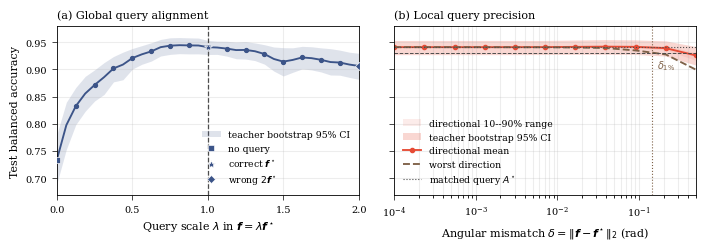

saved /home/felix/SAR-QML/notebooks/query_sensitivity_outputs/query_sensitivity_paper_ff678e764ac1.pdf


In [17]:
# =============================================================================
# Manuscript figure
# =============================================================================
COLORS = {
    "global": "#3C5488",
    "local": "#E64B35",
    "worst": "#7E6148",
    "reference": "#4D4D4D",
}

mpl.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "axes.linewidth": 0.6,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "lines.linewidth": 1.35,
        "legend.fontsize": 6.7,
    }
)

fig, axes = plt.subplots(1, 2, figsize=(7.1, 2.55), sharey=True)

# (a) Global path
axis = axes[0]
axis.fill_between(
    GLOBAL_X,
    GLOBAL_SUMMARY["lower"],
    GLOBAL_SUMMARY["upper"],
    color=COLORS["global"],
    alpha=0.16,
    lw=0,
    label="teacher bootstrap 95% CI",
)
axis.plot(
    GLOBAL_X,
    GLOBAL_SUMMARY["mean"],
    "-o",
    color=COLORS["global"],
    ms=2.8,
    markevery=max(1, len(GLOBAL_X) // 16),
)
axis.axvline(1.0, color=COLORS["reference"], lw=0.9, ls="--")
for lam, marker, label in [
    (0.0, "s", "no query"),
    (1.0, "*", r"correct $\boldsymbol{f}^\star$"),
    (2.0, "D", r"wrong $2\boldsymbol{f}^\star$"),
]:
    index = int(np.argmin(np.abs(GLOBAL_X - lam)))
    axis.plot(
        GLOBAL_X[index],
        GLOBAL_SUMMARY["mean"][index],
        marker=marker,
        color=COLORS["global"],
        mec="white",
        mew=0.45,
        ms=6 if marker == "*" else 4,
        ls="none",
        label=label,
        zorder=5,
    )
axis.set_xlim(0.0, 2.0)
axis.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
axis.set_xlabel(r"Query scale $\lambda$ in $\boldsymbol{f}=\lambda\boldsymbol{f}^\star$")
axis.set_ylabel("Test balanced accuracy")
axis.set_title("(a) Global query alignment", loc="left")
axis.grid(True, alpha=0.22)
axis.legend(frameon=False, loc="best", ncol=1)

# (b) Local neighborhood
axis = axes[1]
axis.fill_between(
    LOCAL_X,
    DIRECTION_LOWER,
    DIRECTION_UPPER,
    color=COLORS["local"],
    alpha=0.10,
    lw=0,
    label="directional 10--90% range",
)
axis.fill_between(
    LOCAL_X,
    LOCAL_MEAN_SUMMARY["lower"],
    LOCAL_MEAN_SUMMARY["upper"],
    color=COLORS["local"],
    alpha=0.22,
    lw=0,
    label="teacher bootstrap 95% CI",
)
axis.plot(
    LOCAL_X,
    LOCAL_MEAN_SUMMARY["mean"],
    "-o",
    color=COLORS["local"],
    ms=3.0,
    label="directional mean",
)
axis.plot(
    LOCAL_X,
    LOCAL_WORST_SUMMARY["mean"],
    "--",
    color=COLORS["worst"],
    label="worst direction",
)
axis.axhline(
    A_STAR,
    color=COLORS["reference"],
    lw=0.8,
    ls=":",
    label=r"matched query $A^\star$",
)
axis.axhline(
    A_THRESHOLD,
    color=COLORS["reference"],
    lw=0.7,
    ls="--",
)
axis.axvline(
    DELTA_TOLERANCE,
    color=COLORS["worst"],
    lw=0.8,
    ls=":",
)
if TOLERANCE_STATUS == "resolved":
    tolerance_label = r"$\delta_{1\%}$"
elif TOLERANCE_STATUS == "lower_bound":
    tolerance_label = r"$\delta_{1\%}>\delta_{\max}$"
else:
    tolerance_label = r"$\delta_{1\%}<\delta_{\min}$"
axis.annotate(
    tolerance_label,
    xy=(DELTA_TOLERANCE, A_THRESHOLD),
    xytext=(-5 if TOLERANCE_STATUS == "lower_bound" else 4, -11),
    textcoords="offset points",
    fontsize=7,
    color=COLORS["worst"],
    ha="right" if TOLERANCE_STATUS == "lower_bound" else "left",
)
axis.set_xscale("log")
axis.set_xlim(LOCAL_X.min(), LOCAL_X.max())
axis.set_xlabel(r"Angular mismatch $\delta=\|\boldsymbol{f}-\boldsymbol{f}^\star\|_2$ (rad)")
axis.set_title("(b) Local query precision", loc="left")
axis.grid(True, which="both", alpha=0.22)
axis.legend(frameon=False, loc="best")

all_lower = np.concatenate(
    [GLOBAL_SUMMARY["lower"], LOCAL_MEAN_SUMMARY["lower"], [A_THRESHOLD]]
)
all_upper = np.concatenate(
    [GLOBAL_SUMMARY["upper"], LOCAL_MEAN_SUMMARY["upper"], [A_STAR]]
)
y_pad = max(0.015, 0.08 * (all_upper.max() - all_lower.min()))
axes[0].set_ylim(max(0.45, all_lower.min() - y_pad), min(1.01, all_upper.max() + y_pad))

fig.tight_layout(w_pad=1.4)
figure_stem = OUTDIR / f"query_sensitivity_{PROFILE}_{RUN_ID}"
fig.savefig(figure_stem.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(figure_stem.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.show()

print(f"saved {figure_stem.with_suffix('.pdf').resolve()}")

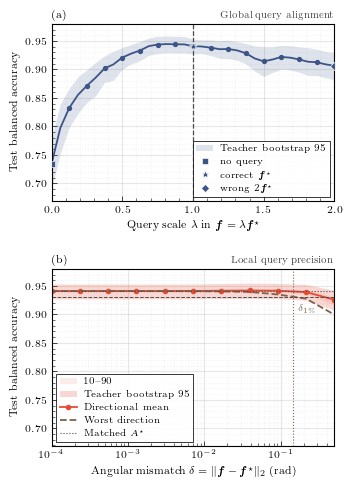

Saved: /home/felix/SAR-QML/notebooks/query_sensitivity_outputs/query_sensitivity_paper_ff678e764ac1.pdf


In [20]:
import os
import shutil
import subprocess

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# =============================================================================
# LaTeX Probing & Environment Setup
# =============================================================================

def latex_is_usable():
    if shutil.which("latex") is None or shutil.which("dvipng") is None:
        return False
    try:
        completed = subprocess.run(
            ["kpsewhich", "latex.ltx"],
            capture_output=True,
            timeout=30,
            check=False,
        )
    except (OSError, subprocess.SubprocessError):
        return False
    return completed.returncode == 0 and bool(completed.stdout.strip())


USE_TEX_REQUESTED = os.environ.get("USE_TEX", "1") == "1"
USE_TEX = USE_TEX_REQUESTED and latex_is_usable()
DASH = "--" if USE_TEX else "\u2013"


def configure_matplotlib():
    """Compact single-column paper styling."""
    mpl.rcParams.update(
        {
            "text.usetex": USE_TEX,
            "text.latex.preamble": r"\usepackage{amsmath}\usepackage{bm}",
            "font.family": "serif",
            "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
            "mathtext.fontset": "cm",
            "font.size": 8,
            "axes.labelsize": 8,
            "axes.titlesize": 8,
            "axes.linewidth": 0.6,
            "axes.spines.top": True,
            "axes.spines.right": True,
            "xtick.labelsize": 7.5,
            "ytick.labelsize": 7.5,
            "xtick.major.width": 0.5,
            "ytick.major.width": 0.5,
            "xtick.minor.width": 0.4,
            "ytick.minor.width": 0.4,
            "xtick.direction": "in",
            "ytick.direction": "in",
            "legend.fontsize": 6.7,
            "legend.handlelength": 1.8,
            "legend.columnspacing": 1.0,
            "lines.linewidth": 1.3,
            "savefig.bbox": None,
        }
    )


def panel_title(axis, letter, description):
    """Bold panel letter on the left, description on the right."""
    axis.set_title(letter, loc="left", pad=4, fontweight="bold")
    axis.set_title(description, loc="right", pad=4, fontsize=7.0, color="0.25")


def finish_axis(axis, x_minor=True, y_minor=True, grid_axis="both"):
    """Gridlines, minor ticks and spines applied consistently across panels."""
    axis.set_axisbelow(True)
    axis.minorticks_on()
    if not x_minor:
        axis.xaxis.set_minor_locator(mticker.NullLocator())
    if not y_minor:
        axis.yaxis.set_minor_locator(mticker.NullLocator())
    axis.tick_params(which="both", top=False, right=False)
    axis.grid(True, which="major", axis=grid_axis, linestyle="-", alpha=0.30)
    axis.grid(True, which="minor", axis=grid_axis, linestyle=":", alpha=0.15)
    for spine in axis.spines.values():
        spine.set_linewidth(0.8)


# =============================================================================
# Color Palette & Series Identity
# =============================================================================

COLORS = {
    "global": "#3C5488",
    "local": "#E64B35",
    "worst": "#7E6148",
    "reference": "#4D4D4D",
}

# =============================================================================
# Plotting Execution
# =============================================================================

configure_matplotlib()

# Single-column stacked figure setup (3.45 in width)
fig, axes = plt.subplots(2, 1, figsize=(3.45, 4.90), sharey=True)

# -----------------------------------------------------------------------------
# Panel (a): Global Query Alignment
# -----------------------------------------------------------------------------
axis_a = axes[0]
axis_a.fill_between(
    GLOBAL_X,
    GLOBAL_SUMMARY["lower"],
    GLOBAL_SUMMARY["upper"],
    color=COLORS["global"],
    alpha=0.16,
    lw=0,
    label="Teacher bootstrap 95% CI",
)
axis_a.plot(
    GLOBAL_X,
    GLOBAL_SUMMARY["mean"],
    "-o",
    color=COLORS["global"],
    ms=2.8,
    markevery=max(1, len(GLOBAL_X) // 16),
)
axis_a.axvline(1.0, color=COLORS["reference"], lw=0.9, ls="--")

# Key evaluated sample points
for lam, marker, label in [
    (0.0, "s", "no query"),
    (1.0, "*", r"correct $\boldsymbol{f}^\star$"),
    (2.0, "D", r"wrong $2\boldsymbol{f}^\star$"),
]:
    idx = int(np.argmin(np.abs(GLOBAL_X - lam)))
    axis_a.plot(
        GLOBAL_X[idx],
        GLOBAL_SUMMARY["mean"][idx],
        marker=marker,
        color=COLORS["global"],
        mec="white",
        mew=0.45,
        ms=6 if marker == "*" else 4,
        ls="none",
        label=label,
        zorder=5,
    )

axis_a.set_xlim(0.0, 2.0)
axis_a.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
axis_a.set_xlabel(r"Query scale $\lambda$ in $\boldsymbol{f}=\lambda\boldsymbol{f}^\star$")
axis_a.set_ylabel("Test balanced accuracy")
panel_title(axis_a, "(a)", "Global query alignment")
finish_axis(axis_a, x_minor=True)

# Framed legend for Panel (a)
leg_a = axis_a.legend(
    loc="lower right",
    frameon=True,
    framealpha=0.9,
    edgecolor="black",
    fancybox=False,
)
leg_a.get_frame().set_linewidth(0.6)

# -----------------------------------------------------------------------------
# Panel (b): Local Query Precision
# -----------------------------------------------------------------------------
axis_b = axes[1]
axis_b.fill_between(
    LOCAL_X,
    DIRECTION_LOWER,
    DIRECTION_UPPER,
    color=COLORS["local"],
    alpha=0.10,
    lw=0,
    label=r"10--90% directional range",
)
axis_b.fill_between(
    LOCAL_X,
    LOCAL_MEAN_SUMMARY["lower"],
    LOCAL_MEAN_SUMMARY["upper"],
    color=COLORS["local"],
    alpha=0.22,
    lw=0,
    label="Teacher bootstrap 95% CI",
)
axis_b.plot(
    LOCAL_X,
    LOCAL_MEAN_SUMMARY["mean"],
    "-o",
    color=COLORS["local"],
    ms=3.0,
    label="Directional mean",
)
axis_b.plot(
    LOCAL_X,
    LOCAL_WORST_SUMMARY["mean"],
    "--",
    color=COLORS["worst"],
    label="Worst direction",
)
axis_b.axhline(
    A_STAR,
    color=COLORS["reference"],
    lw=0.8,
    ls=":",
    label=r"Matched $A^\star$",
)
axis_b.axhline(
    A_THRESHOLD,
    color=COLORS["reference"],
    lw=0.7,
    ls="--",
)
axis_b.axvline(
    DELTA_TOLERANCE,
    color=COLORS["worst"],
    lw=0.8,
    ls=":",
)

if TOLERANCE_STATUS == "resolved":
    tolerance_label = r"$\delta_{1\%}$"
elif TOLERANCE_STATUS == "lower_bound":
    tolerance_label = r"$\delta_{1\%}>\delta_{\max}$"
else:
    tolerance_label = r"$\delta_{1\%}<\delta_{\min}$"

axis_b.annotate(
    tolerance_label,
    xy=(DELTA_TOLERANCE, A_THRESHOLD),
    xytext=(-5 if TOLERANCE_STATUS == "lower_bound" else 4, -11),
    textcoords="offset points",
    fontsize=7,
    color=COLORS["worst"],
    ha="right" if TOLERANCE_STATUS == "lower_bound" else "left",
)
axis_b.set_xscale("log")
axis_b.set_xlim(LOCAL_X.min(), LOCAL_X.max())
axis_b.set_xlabel(r"Angular mismatch $\delta=\|\boldsymbol{f}-\boldsymbol{f}^\star\|_2$ (rad)")
axis_b.set_ylabel("Test balanced accuracy")
panel_title(axis_b, "(b)", "Local query precision")
finish_axis(axis_b, x_minor=True)

# Framed legend for Panel (b)
leg_b = axis_b.legend(
    loc="lower left",
    frameon=True,
    framealpha=0.9,
    edgecolor="black",
    fancybox=False,
)
leg_b.get_frame().set_linewidth(0.6)

# -----------------------------------------------------------------------------
# Dynamic Y-axis limits & Subplot Adjustment
# -----------------------------------------------------------------------------
all_lower = np.concatenate(
    [GLOBAL_SUMMARY["lower"], LOCAL_MEAN_SUMMARY["lower"], [A_THRESHOLD]]
)
all_upper = np.concatenate(
    [GLOBAL_SUMMARY["upper"], LOCAL_MEAN_SUMMARY["upper"], [A_STAR]]
)
y_pad = max(0.015, 0.08 * (all_upper.max() - all_lower.min()))
axes[0].set_ylim(max(0.45, all_lower.min() - y_pad), min(1.01, all_upper.max() + y_pad))

fig.subplots_adjust(
    left=0.165,
    right=0.985,
    bottom=0.078,
    top=0.940,
    hspace=0.38,
)

figure_stem = OUTDIR / f"query_sensitivity_{PROFILE}_{RUN_ID}"
fig.savefig("query_sensitivity_.pdf", pad_inches=0.05, bbox_inches="tight")
# fig.savefig(
#     figure_stem.with_suffix(".png"),
#     dpi=600,
#     pad_inches=0.05,
#     bbox_inches="tight",
# )

if USE_TEX_REQUESTED and not USE_TEX:
    print(
        "Note: usetex was requested but this installation cannot serve it; "
        "the figure was rendered with mathtext instead."
    )

plt.show()
print(f"Saved: {figure_stem.with_suffix('.pdf').resolve()}")

## Numerical summary and manuscript wording

The global maximum is reported only along the predeclared ray. Together with
the direction-resolved local scan, the figure establishes alignment on that
path and local sensitivity around \(\boldsymbol f^\star\); it does not by
itself prove uniqueness over the entire two-dimensional query torus.

In [18]:
# =============================================================================
# Save compact summaries and a caption draft
# =============================================================================
global_table = pd.DataFrame(
    {
        "query_scale": GLOBAL_X,
        "mean": GLOBAL_SUMMARY["mean"],
        "lower95": GLOBAL_SUMMARY["lower"],
        "upper95": GLOBAL_SUMMARY["upper"],
    }
)
local_table = pd.DataFrame(
    {
        "delta": LOCAL_X,
        "directional_mean": LOCAL_MEAN_SUMMARY["mean"],
        "mean_lower95": LOCAL_MEAN_SUMMARY["lower"],
        "mean_upper95": LOCAL_MEAN_SUMMARY["upper"],
        "direction_q10": DIRECTION_LOWER,
        "direction_q90": DIRECTION_UPPER,
        "worst_direction": LOCAL_WORST_SUMMARY["mean"],
        "worst_lower95": LOCAL_WORST_SUMMARY["lower"],
        "worst_upper95": LOCAL_WORST_SUMMARY["upper"],
    }
)

global_table.to_csv(
    OUTDIR / f"global_summary_{PROFILE}_{RUN_ID}.csv", index=False
)
local_table.to_csv(
    OUTDIR / f"local_summary_{PROFILE}_{RUN_ID}.csv", index=False
)

tolerance_summary = {
    "A_star": A_STAR,
    "global_peak_scale": GLOBAL_PEAK_SCALE,
    "global_peak_accuracy": GLOBAL_PEAK_ACCURACY,
    "accuracy_drop": ACCURACY_DROP,
    "threshold": A_THRESHOLD,
    "delta_tolerance_rad": DELTA_TOLERANCE,
    "status": TOLERANCE_STATUS,
    "bootstrap_lower95": float(TOLERANCE_CI[0]),
    "bootstrap_upper95": float(TOLERANCE_CI[1]),
    "bootstrap_censoring_counts": {
        status: int(tolerance_statuses.count(status))
        for status in sorted(set(tolerance_statuses))
    },
}
(OUTDIR / f"tolerance_{PROFILE}_{RUN_ID}.json").write_text(
    json.dumps(tolerance_summary, indent=2)
)

if TOLERANCE_STATUS == "resolved":
    tolerance_caption = (
        r"The marked tolerance $\delta_{1\%}$ estimates the largest angular "
        r"mismatch for which the worst-direction accuracy remains within one "
        r"percentage point of its matched-query value."
    )
elif TOLERANCE_STATUS == "lower_bound":
    tolerance_caption = (
        rf"The worst-direction loss remains below one percentage point up to "
        rf"$\delta={LOCAL_X.max():.3g}$ rad, giving only a lower bound on "
        rf"$\delta_{{1\%}}$."
    )
else:
    tolerance_caption = (
        rf"The worst-direction loss exceeds one percentage point by "
        rf"$\delta={LOCAL_X.min():.3g}$ rad, giving only an upper bound on "
        rf"$\delta_{{1\%}}$."
    )

caption = rf"""\textbf{{Classification sensitivity to the fixed query value.}}
(a) Test balanced accuracy for students trained with
$\boldsymbol f(\lambda)=\lambda\boldsymbol f^\star$, where
$\boldsymbol f^\star=(\pi/4,\pi/3)$ is the query used to generate the teacher
labels. The values $\lambda=0$, $1$, and $2$ correspond to the no-query,
correct-query, and mismatched-query models, respectively.
(b) Local sensitivity to perturbations
$\boldsymbol f=\boldsymbol f^\star+\delta(\cos\phi,\sin\phi)$.
The solid curve denotes the directional mean, the light band the directional
$10$--$90\%$ range, and the dashed curve the worst-direction accuracy.
{tolerance_caption} Parameters are retrained independently for every query;
shaded confidence intervals are obtained by paired bootstrap resampling over
teacher instances."""
caption_path = OUTDIR / f"caption_{PROFILE}_{RUN_ID}.tex"
caption_path.write_text(caption)

display(global_table)
display(local_table)
print(json.dumps(tolerance_summary, indent=2))
print("\nCaption draft:\n")
print(caption)

if PROFILE != "paper":
    print(
        "\nThis is a smoke-test result only. Set PROFILE='paper', restart the "
        "kernel, and run all cells before using the figure or tolerance."
    )

,query_scale,mean,lower95,upper95
0,0.0000,0.734112,0.690182,0.780809
1,0.0625,0.797519,0.752832,0.839659
2,0.1250,0.832373,0.798348,0.866735
3,0.1875,0.855626,0.823090,0.887245
4,0.2500,0.871496,0.842005,0.899310
5,0.3125,0.885784,0.854004,0.912574
6,0.3750,0.901894,0.877153,0.923766
7,0.4375,0.908939,0.881031,0.931799
8,0.5000,0.920946,0.900653,0.938551
9,0.5625,0.927802,0.909475,0.943778


,delta,directional_mean,mean_lower95,mean_upper95,direction_q10,direction_q90,worst_direction,worst_lower95,worst_upper95
0,0.000100,0.941059,0.927197,0.953349,0.941055,0.941063,0.941047,0.927383,0.953563
1,0.000234,0.941061,0.927201,0.953352,0.941056,0.941067,0.941043,0.927378,0.953554
2,0.000549,0.941056,0.927196,0.953344,0.941049,0.941062,0.941023,0.927354,0.953527
3,0.001287,0.941054,0.927194,0.953348,0.941048,0.941068,0.940981,0.927323,0.953477
4,0.003017,0.941049,0.927186,0.953347,0.941036,0.941065,0.940899,0.927229,0.953375
5,0.007071,0.941177,0.927439,0.953357,0.940994,0.941416,0.940792,0.927149,0.953258
6,0.016572,0.941538,0.927704,0.954116,0.941016,0.941963,0.940403,0.926841,0.952803
7,0.038840,0.941986,0.927843,0.954919,0.941183,0.943279,0.939460,0.926014,0.951772
8,0.091028,0.941633,0.927522,0.954391,0.939415,0.943810,0.934959,0.921520,0.948031
9,0.213340,0.939164,0.924643,0.952576,0.936005,0.943613,0.927597,0.912881,0.942496


{
  "A_star": 0.9410589321387397,
  "global_peak_scale": 0.8125,
  "global_peak_accuracy": 0.9446506836087648,
  "accuracy_drop": 0.01,
  "threshold": 0.9310589321387397,
  "delta_tolerance_rad": 0.14293334123753443,
  "status": "resolved",
  "bootstrap_lower95": 0.10596165791718,
  "bootstrap_upper95": 0.23289495531863774,
  "bootstrap_censoring_counts": {
    "resolved": 5000
  }
}

Caption draft:

\textbf{Classification sensitivity to the fixed query value.}
(a) Test balanced accuracy for students trained with
$\boldsymbol f(\lambda)=\lambda\boldsymbol f^\star$, where
$\boldsymbol f^\star=(\pi/4,\pi/3)$ is the query used to generate the teacher
labels. The values $\lambda=0$, $1$, and $2$ correspond to the no-query,
correct-query, and mismatched-query models, respectively.
(b) Local sensitivity to perturbations
$\boldsymbol f=\boldsymbol f^\star+\delta(\cos\phi,\sin\phi)$.
The solid curve denotes the directional mean, the light band the directional
$10$--$90\%$ range, and the dashed